# Starting Spark

In [1]:
import shutil
from pyspark.sql import *
from pyspark.sql.types import *
from delta import *
from pathlib import Path

builder = (
    SparkSession
        .builder
        .appName("Pollen")
        .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension")
        .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog")
)

# Utworzenie sesji.
session = configure_spark_with_delta_pip(builder).getOrCreate()

# Konfiguracja dodatkowych parametrów sesji po jej utworzeniu.
session.conf.set("spark.sql.shuffle.partitions", "20")

:: loading settings :: url = jar:file:/opt/spark-4.2.0-bin-hadoop3/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /home/Binny/.ivy2.5.2/cache
The jars for the packages stored in: /home/Binny/.ivy2.5.2/jars
io.delta#delta-spark_4.2_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-a109ff51-fbc3-4f70-8c26-abd9f13c5181;1.0
	confs: [default]
	found io.delta#delta-spark_4.2_2.13;4.4.1 in central
	found io.delta#delta-storage;4.4.1 in central
	found io.unitycatalog#unitycatalog-client;0.6.0 in central
	found org.slf4j#slf4j-api;2.0.13 in central
	found org.apache.logging.log4j#log4j-slf4j2-impl;2.25.3 in central
	found org.apache.logging.log4j#log4j-api;2.25.3 in central
	found com.google.code.findbugs#jsr305;3.0.2 in central
	found io.unitycatalog#unitycatalog-hadoop;0.6.0 in central
	found org.apache.logging.log4j#log4j-core;2.25.3 in central
	found io.delta#delta-kernel-api;4.4.1 in central
	found org.r

### Reading data

In [28]:
pollen_path = 'data/delta/pollen_historical'
pollen_df = (
    session.read
    .format("delta")
    .load(pollen_path)
)

# Verification: Print row count and schema to confirm data is loaded correctly
print(f"Total rows loaded: {pollen_df.count()}")
pollen_df.printSchema()

Total rows loaded: 142247
root
 |-- station_abbr: string (nullable = true)
 |-- reference_timestamp: string (nullable = true)
 |-- kaalnud0: double (nullable = true)
 |-- kabetud0: double (nullable = true)
 |-- kacoryd0: double (nullable = true)
 |-- kafagud0: double (nullable = true)
 |-- kafraxd0: double (nullable = true)
 |-- kaquerd0: double (nullable = true)
 |-- khpoacd0: double (nullable = true)



# Cleaning data

In [19]:
from pyspark.sql import functions as F

# 1. Automatically filter columns that are of type 'double' or 'float' (where NaNs can occur)
numerical_cols = [c for c, dtype in pollen_df.dtypes if dtype in ('double', 'float')]

print(f"Checking numerical columns: {numerical_cols}")

# 2. Count NaNs and nulls only for those numerical columns
nan_counts = pollen_df.select([
    F.count(F.when(F.col(c).isNaN(), c)).alias(c)
    for c in numerical_cols
])

nan_counts.show(truncate=False)

Checking numerical columns: ['kaalnud0', 'kabetud0', 'kacoryd0', 'kafagud0', 'kafraxd0', 'kaquerd0', 'khpoacd0', 'kaalnud1', 'kabetud1', 'kacoryd1', 'kafagud1', 'kafraxd1', 'kaquerd1', 'khpoacd1']


+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+
|kaalnud0|kabetud0|kacoryd0|kafagud0|kafraxd0|kaquerd0|khpoacd0|kaalnud1|kabetud1|kacoryd1|kafagud1|kafraxd1|kaquerd1|khpoacd1|
+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+
|289     |203     |290     |333     |344     |320     |202     |104748  |104814  |104743  |104802  |104810  |104802  |104832  |
+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+



In [9]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

# 1. Define window partitioned by station and ordered by timestamp
window_spec = Window.partitionBy("station_abbr").orderBy("reference_timestamp")

# Choose the column you want to inspect
target_columns = ["kaalnud0", "kabetud0", "kacoryd0", "kafagud0", "kafraxd0", "kaquerd0", "khpoacd0"]

# 2. Flag null/NaN and create a unique ID for each consecutive streak
for target_col in target_columns:
    df_streaks = (
        pollen_df
        # Flag whether the value is null or NaN
        .withColumn("is_null", F.col(target_col).isNull() | F.isnan(F.col(target_col)))
        # Detect when the null status changes from the previous row
        .withColumn("prev_is_null", F.lag("is_null", 1).over(window_spec))
        .withColumn(
            "streak_change",
            F.when((F.col("is_null") != F.col("prev_is_null")) | F.col("prev_is_null").isNull(), 1).otherwise(0)
        )
        # Assign a unique group ID to each consecutive block
        .withColumn("streak_id", F.sum("streak_change").over(window_spec))
    )

    # 3. Aggregate to count the length of each missing data streak
    streak_lengths = (
        df_streaks
        .filter(F.col("is_null") == True)
        .groupBy("station_abbr", "streak_id")
        .agg(F.count("*").alias("consecutive_missing_count"))
    )

    # 4. Filter for streaks greater than 3
    long_gaps = streak_lengths.filter(F.col("consecutive_missing_count") > 3)

    print(f"Found {long_gaps.count()} gaps longer than 3 consecutive missing points for {target_col}:")

Found 0 gaps longer than 3 consecutive missing points for kaalnud0:
+------------+---------+-------------------------+
|station_abbr|streak_id|consecutive_missing_count|
+------------+---------+-------------------------+
+------------+---------+-------------------------+

Found 0 gaps longer than 3 consecutive missing points for kabetud0:
+------------+---------+-------------------------+
|station_abbr|streak_id|consecutive_missing_count|
+------------+---------+-------------------------+
+------------+---------+-------------------------+

Found 0 gaps longer than 3 consecutive missing points for kacoryd0:
+------------+---------+-------------------------+
|station_abbr|streak_id|consecutive_missing_count|
+------------+---------+-------------------------+
+------------+---------+-------------------------+

Found 0 gaps longer than 3 consecutive missing points for kafagud0:
+------------+---------+-------------------------+
|station_abbr|streak_id|consecutive_missing_count|
+----------

In [21]:
# 1. Define windows for forward-fill and backward-fill (for any leading gaps)
fw_window = (
    Window.partitionBy("station_abbr")
    .orderBy("reference_timestamp")
    .rowsBetween(Window.unboundedPreceding, Window.currentRow)
)

bw_window = (
    Window.partitionBy("station_abbr")
    .orderBy(F.col("reference_timestamp").desc())
    .rowsBetween(Window.unboundedPreceding, Window.currentRow)
)

spark_filled_df = pollen_df
for col in target_columns:
    spark_filled_df = (
        spark_filled_df
        # Step 1: Turn NaN into a true SQL NULL so Spark recognizes it as missing
        .withColumn(col, F.when(F.isnan(F.col(col)), None).otherwise(F.col(col)))
        # Step 2: Apply forward-fill, with a fallback to backward-fill for start-of-series gaps
        .withColumn(
            col,
            F.coalesce(
                F.col(col),
                F.last(F.col(col), ignorenulls=True).over(fw_window),
                F.last(F.col(col), ignorenulls=True).over(bw_window)
            )
        )
    )

# 3. Verify that all NaNs and nulls are successfully gone
print("Verification - Remaining missing values:")
verification_counts = spark_filled_df.select([
    F.count(F.when(F.col(c).isNull() | F.isnan(F.col(c)), c)).alias(c)
    for c in target_columns
])
verification_counts.show(truncate=False)

Verification - Remaining missing values:


+--------+--------+--------+--------+--------+--------+--------+
|kaalnud0|kabetud0|kacoryd0|kafagud0|kafraxd0|kaquerd0|khpoacd0|
+--------+--------+--------+--------+--------+--------+--------+
|0       |0       |0       |0       |0       |0       |0       |
+--------+--------+--------+--------+--------+--------+--------+



In [27]:
# 1. Identify columns that end with '1'
cols_to_drop = ["kaalnud1", "kabetud1", "kacoryd1", "kafagud1", "kafraxd1", "kaquerd1", "khpoacd1"]

# 2. Drop those columns from the DataFrame
spark_final_df = spark_filled_df.drop(*cols_to_drop)

# Verify remaining columns
print(f"Remaining columns: {spark_final_df.columns}")

# 4. Save the processed DataFrame into Delta format
(
    spark_final_df.write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")  # Forces Delta to update the table schema with the dropped columns
    .save(pollen_path)
)

print(f"Successfully saved filtered and cleaned data to Delta table at: {pollen_path}")

Remaining columns: ['station_abbr', 'reference_timestamp', 'kaalnud0', 'kabetud0', 'kacoryd0', 'kafagud0', 'kafraxd0', 'kaquerd0', 'khpoacd0']


Successfully saved filtered and cleaned data to Delta table at: data/delta/pollen_historical


# EDA

In [29]:
pollen_df.describe().show()

+-------+------------+-------------------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+
|summary|station_abbr|reference_timestamp|          kaalnud0|          kabetud0|          kacoryd0|          kafagud0|          kafraxd0|          kaquerd0|          khpoacd0|
+-------+------------+-------------------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+
|  count|      142247|             142247|            142247|            142247|            142247|            142247|            142247|            142247|            142247|
|   mean|        NULL|               NULL| 8.490273960083517|22.688520671789213| 6.546992203702011|  3.97072697490984|15.200545529958452|10.052732219308668|19.937003943844157|
| stddev|        NULL|               NULL|49.079298798014506|139.27656758631704|34.293328270480266|28.684914488060326| 8

In [40]:
# 1. Convert string timestamp to a true Spark timestamp using your exact format
spark_parsed_df = pollen_df.withColumn(
    "parsed_timestamp",
    F.to_timestamp(F.col("reference_timestamp"), "dd.MM.yyyy HH:mm")
)

# 2. Filter for the 2010s (2010–2019) directly in Spark to save memory
spark_2010s_df = spark_parsed_df.filter(
    (F.year(F.col("parsed_timestamp")) >= 2010) &
    (F.year(F.col("parsed_timestamp")) <= 2019)
)

print(f"Filtered 2010s row count: {spark_2010s_df.count()}")

Filtered 2010s row count: 35471


/home/Binny/Projects/Pollen/.venv/lib64/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/Binny/Projects/Pollen/.venv/lib64/python3.12/site-packages/pyspark/sql/pandas/types.py:778: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


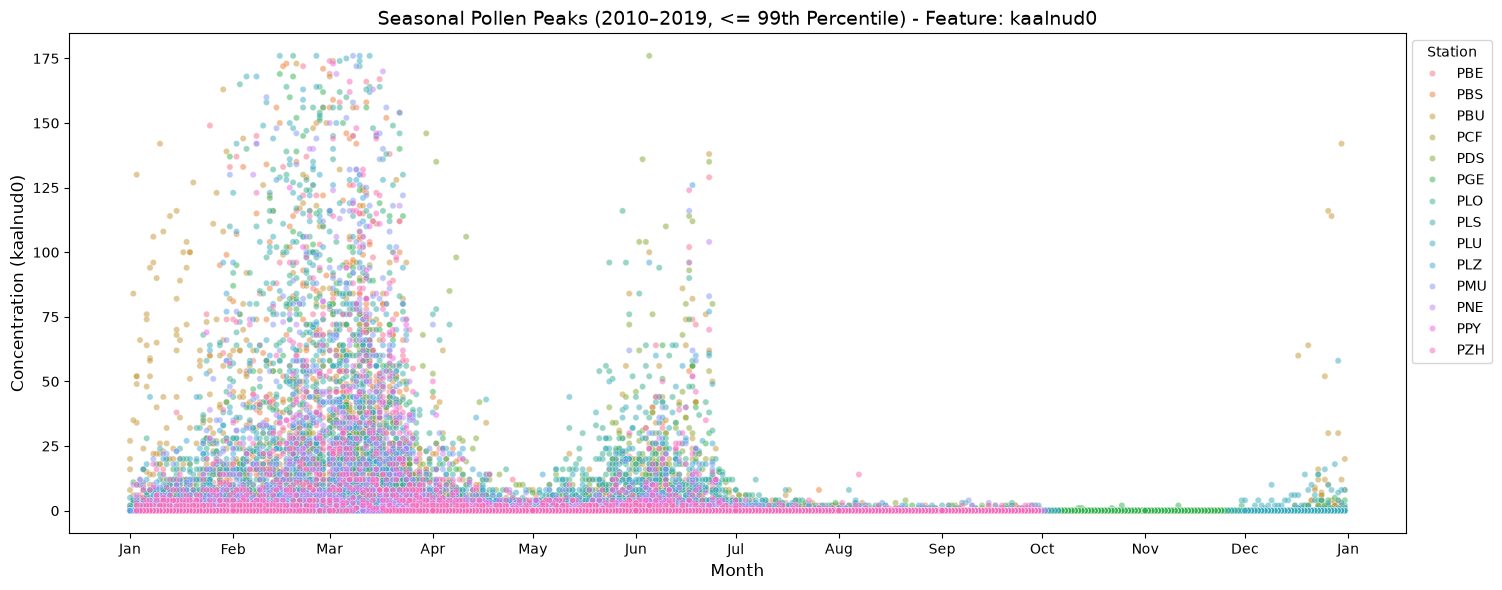

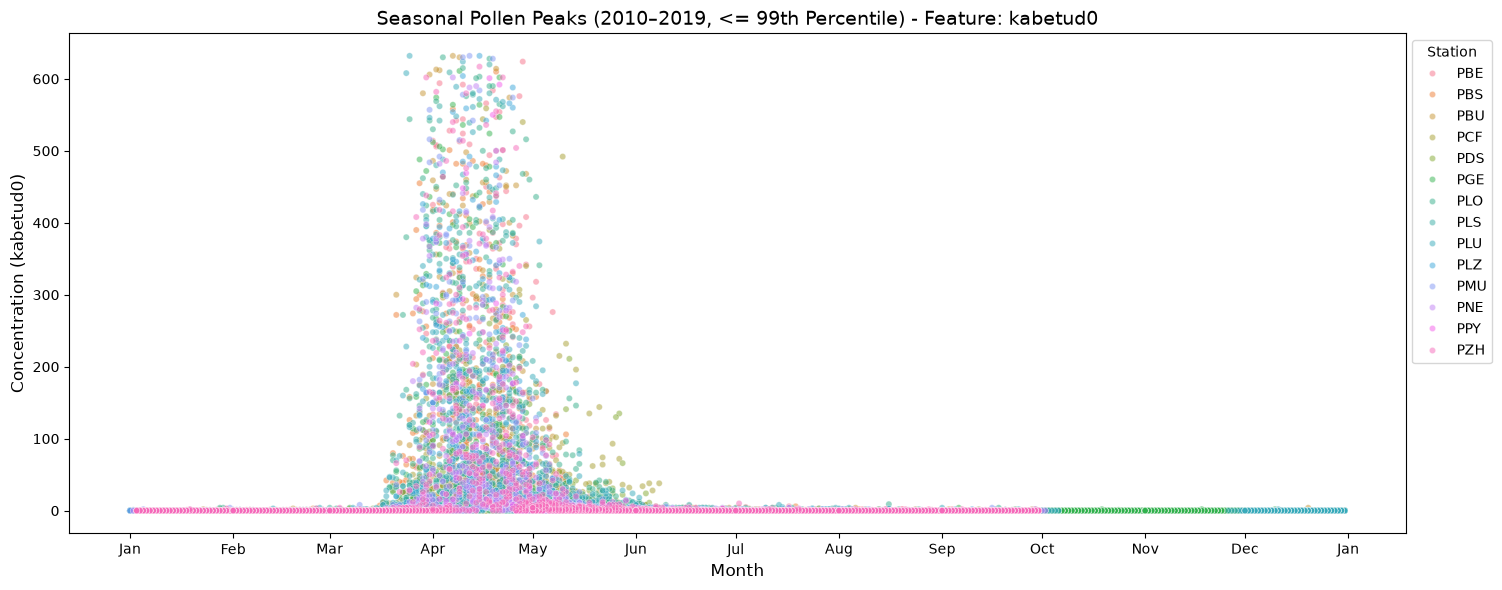

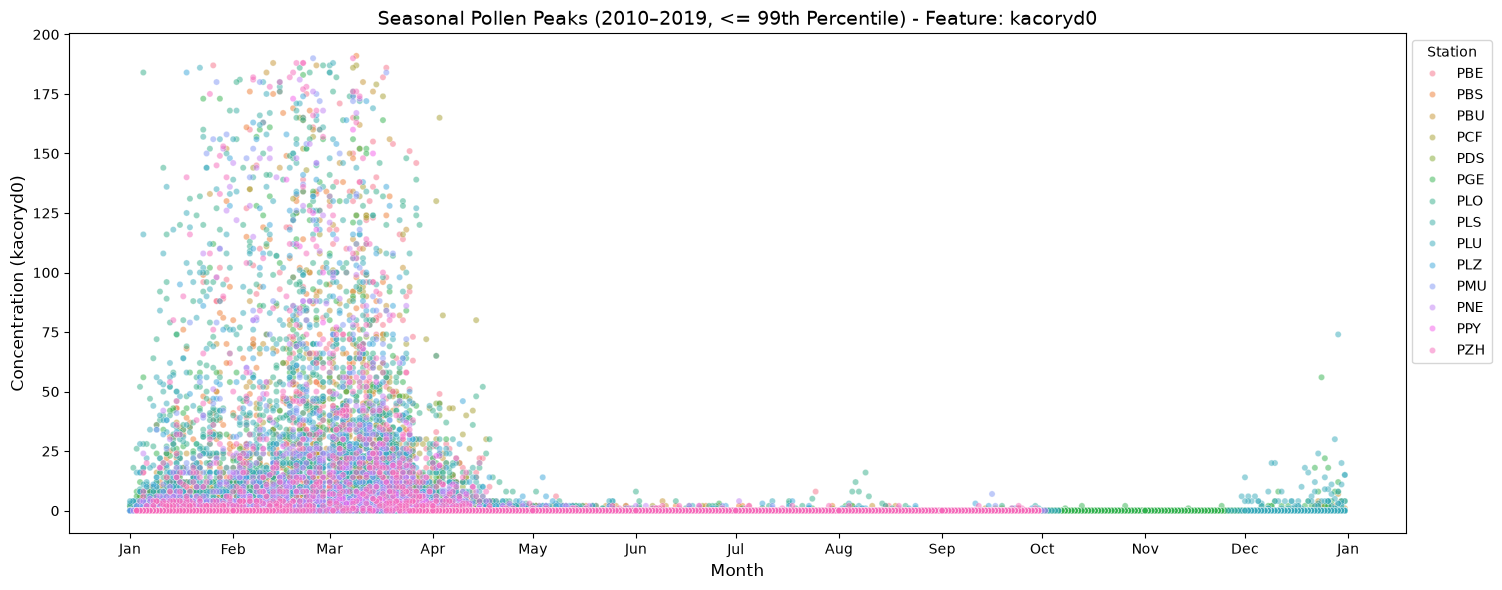

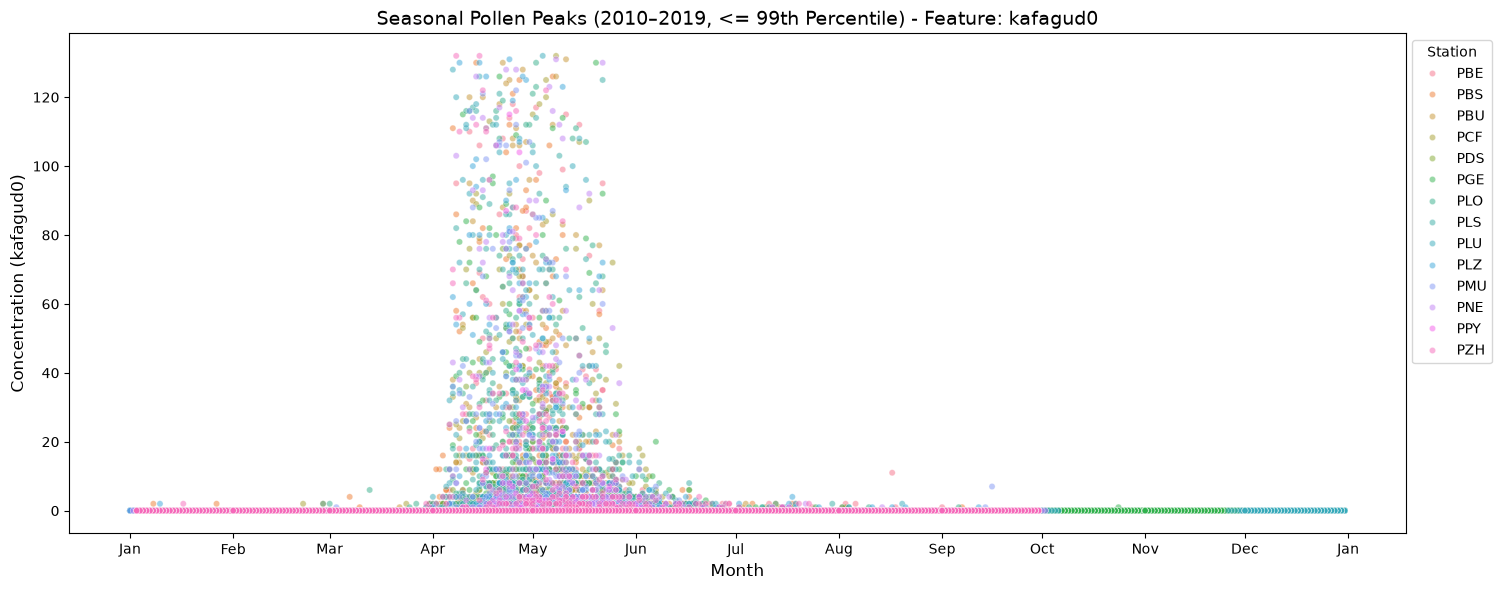

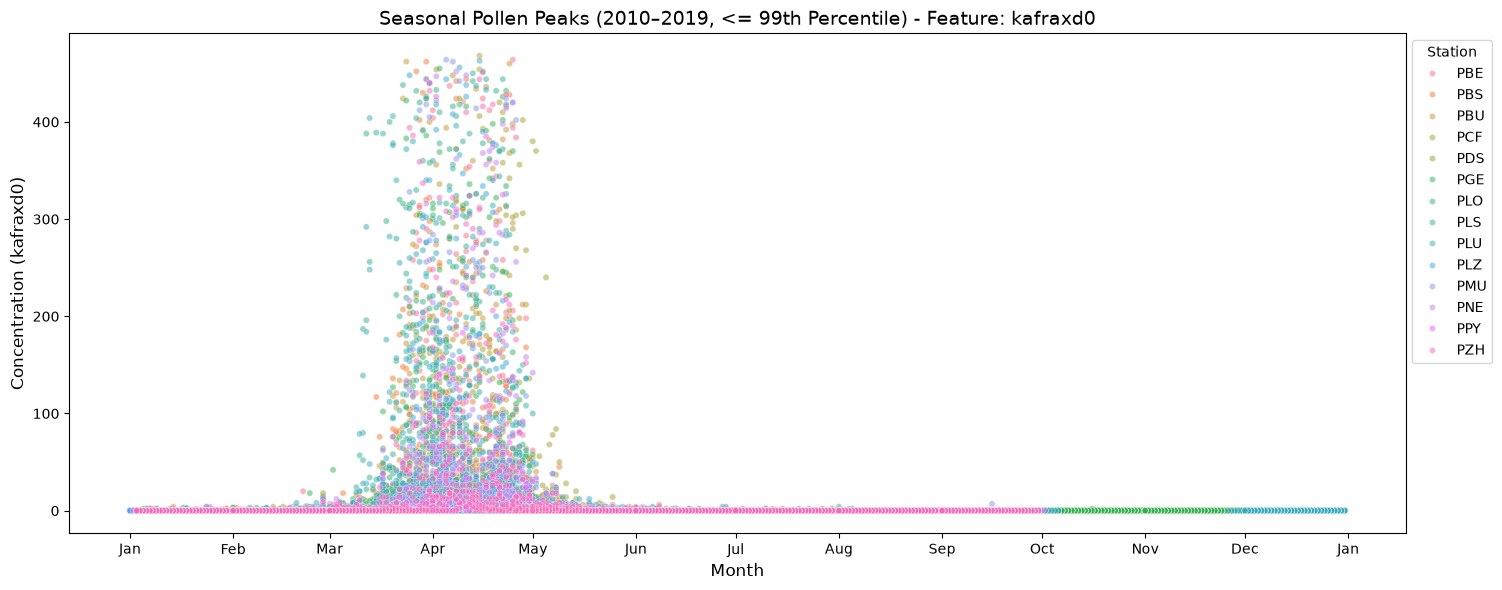

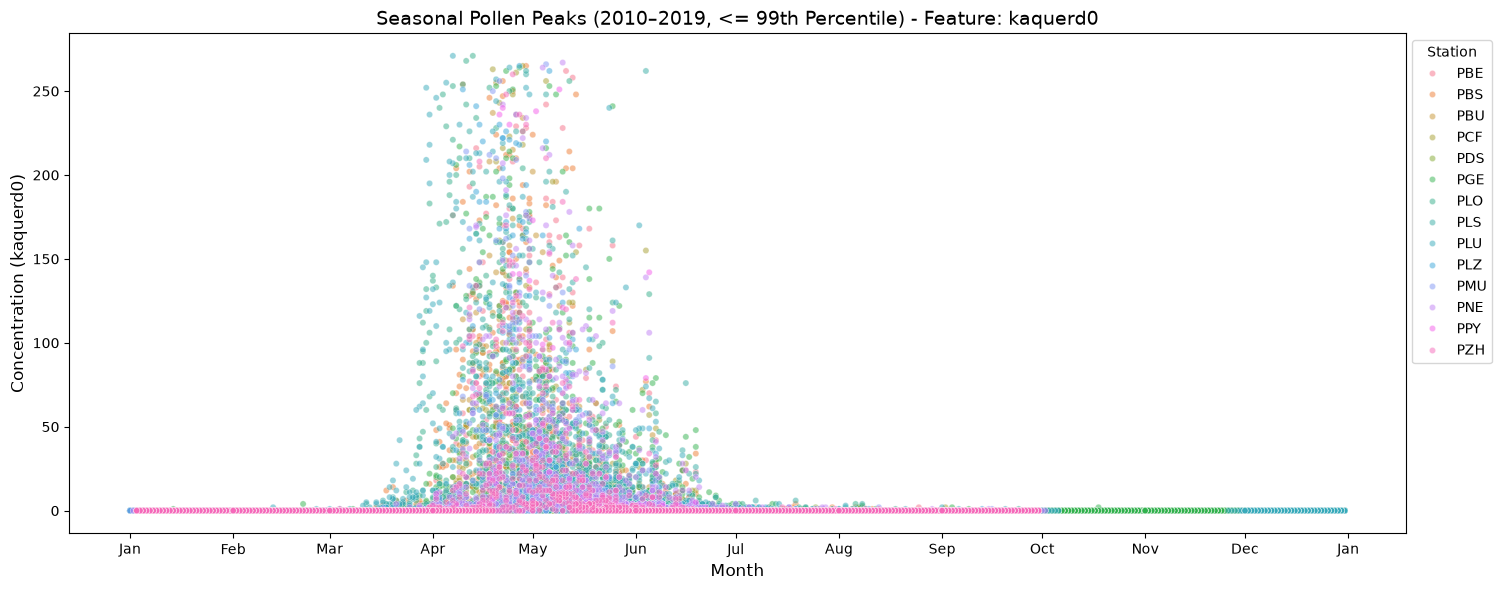

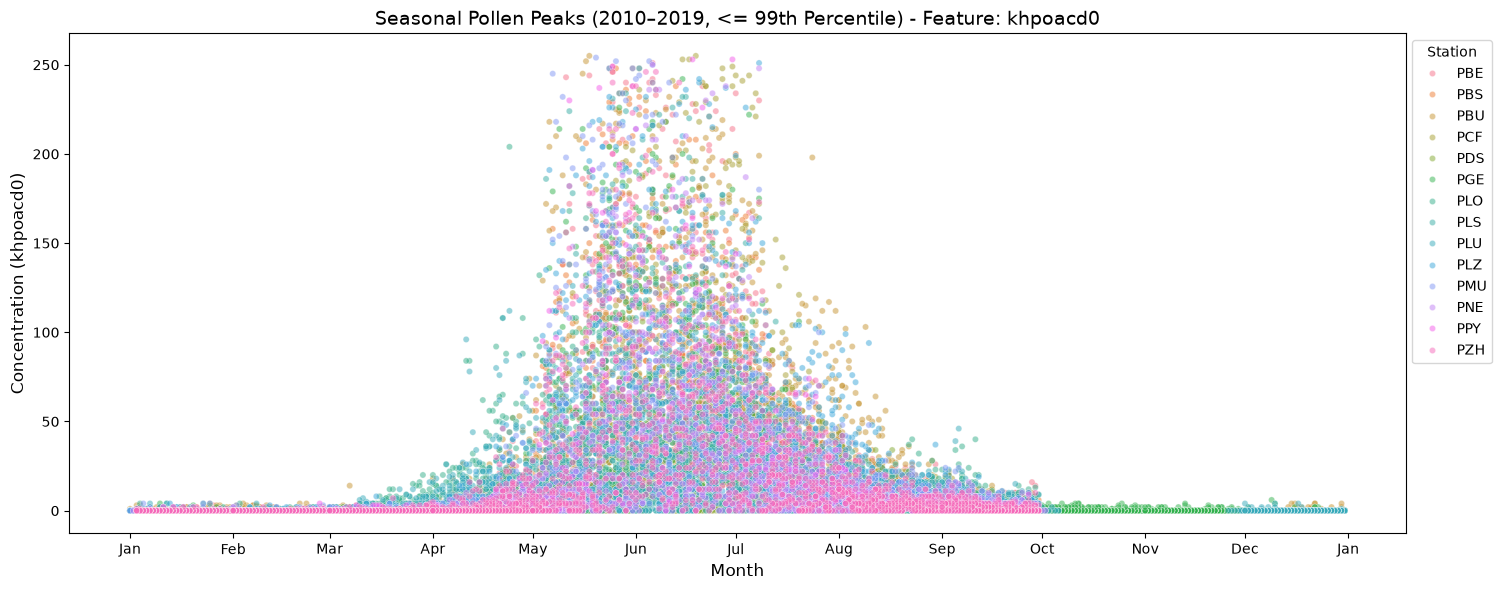

In [65]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import pandas as pd

# 1. Identify pollen features (excluding metadata columns)
exclude_cols = {"station_abbr", "reference_timestamp", "parsed_timestamp"}
pollen_features = [c for c in spark_2010s_df.columns if c not in exclude_cols]

# 2. Pull only the filtered data into Pandas
pdf = spark_2010s_df.toPandas()

# Ensure it's datetime type in Pandas (using your exact format to avoid warnings)
pdf["parsed_timestamp"] = pd.to_datetime(pdf["parsed_timestamp"])

# 3. Strip the year to a dummy year (2000) for seasonal overlay
pdf["date_no_year"] = pdf["parsed_timestamp"].apply(lambda dt: dt.replace(year=2000) if pd.notnull(dt) else dt)

# 4. Loop through each pollen feature and generate a separate dot plot
for feature in pollen_features:
    # 1. Calculate the 99th percentile threshold for the current feature
    p99_threshold = pdf[feature].quantile(0.99)

    # 2. Filter out outliers (keep only values <= 99th percentile)
    pdf_filtered = pdf[pdf[feature] <= p99_threshold]

    # 3. Create the plot for the filtered data
    plt.figure(figsize=(15, 6))

    sns.scatterplot(
        data=pdf_filtered,
        x="date_no_year",
        y=feature,
        hue="station_abbr",
        alpha=0.5,
        s=20
    )

    # Format x-axis to show month names cleanly (Jan, Feb, Mar...)
    ax = plt.gca()
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

    plt.title(f"Seasonal Pollen Peaks (2010–2019, <= 99th Percentile) - Feature: {feature}", fontsize=14)
    plt.xlabel("Month", fontsize=12)
    plt.ylabel(f"Concentration ({feature})", fontsize=12)
    plt.xticks(rotation=0)
    plt.legend(bbox_to_anchor=(1.07, 1), loc="upper right", title="Station")
    plt.tight_layout()
    plt.show()

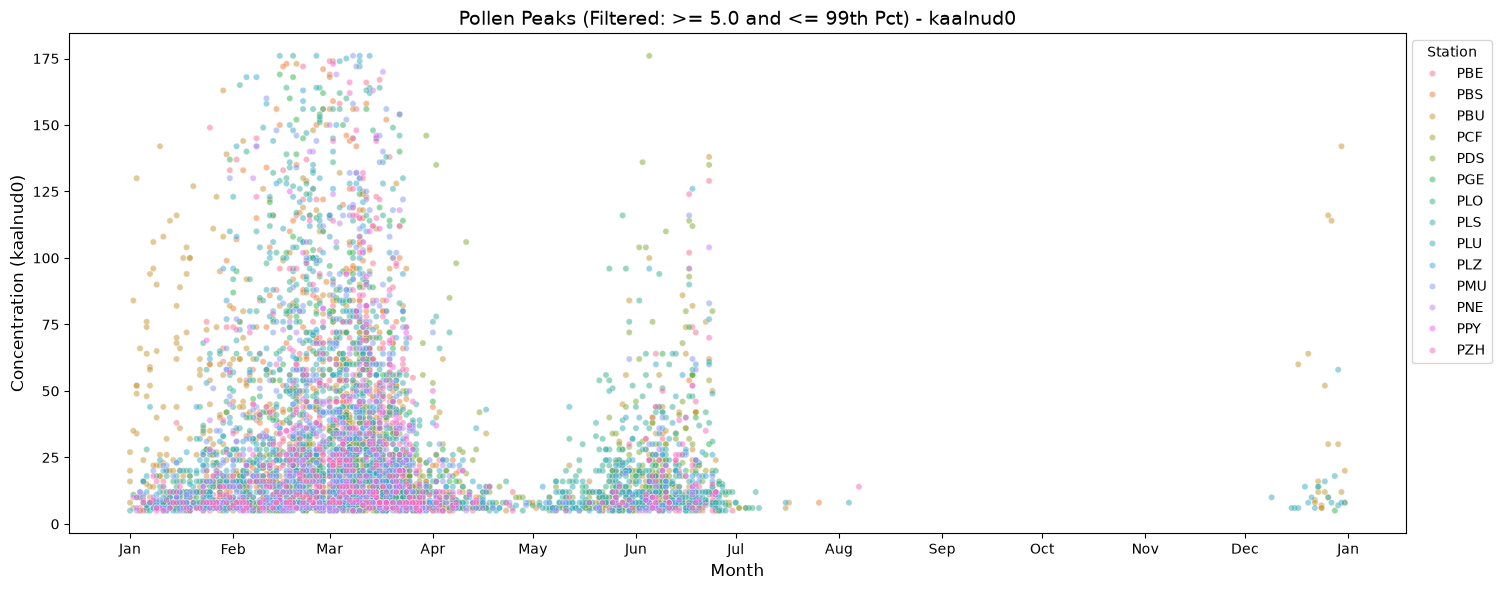

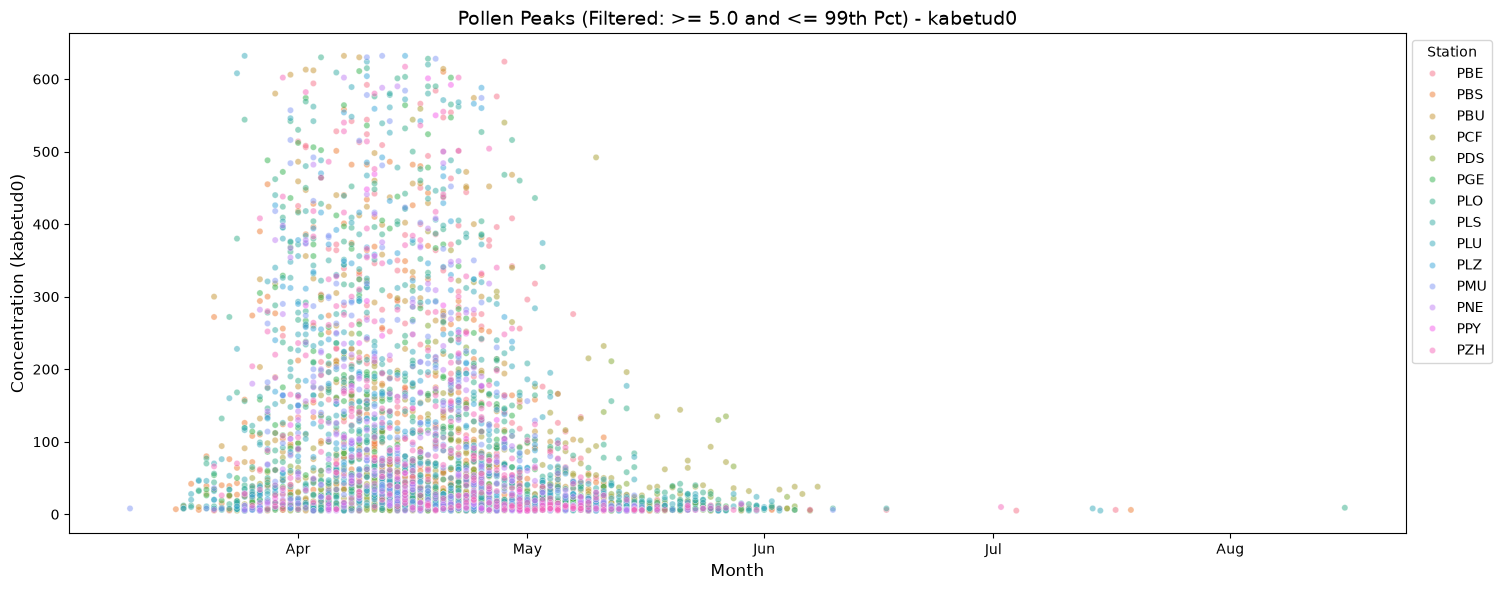

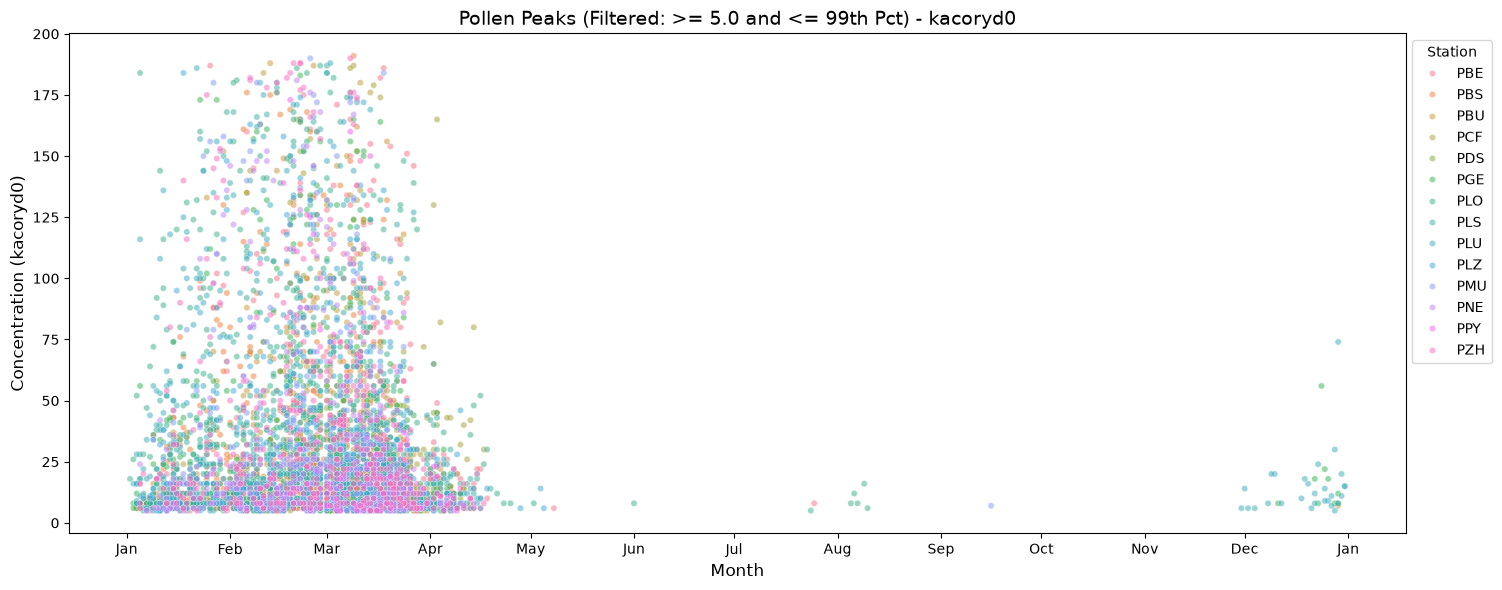

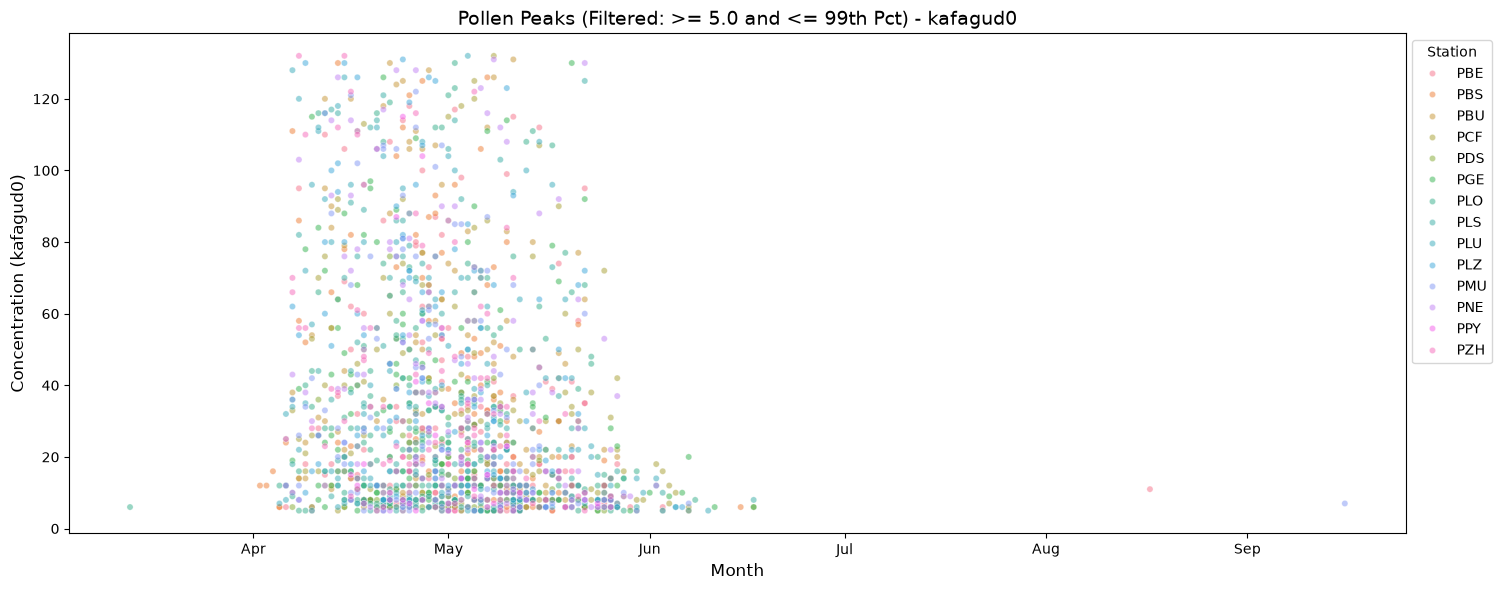

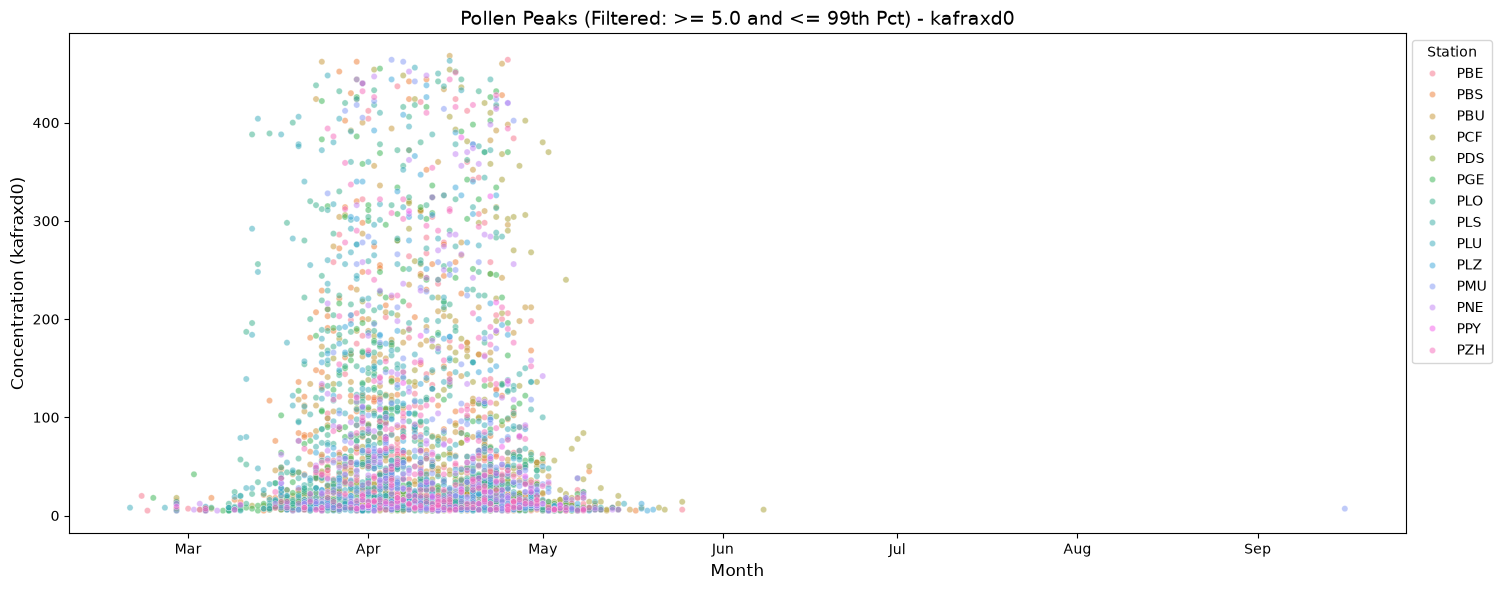

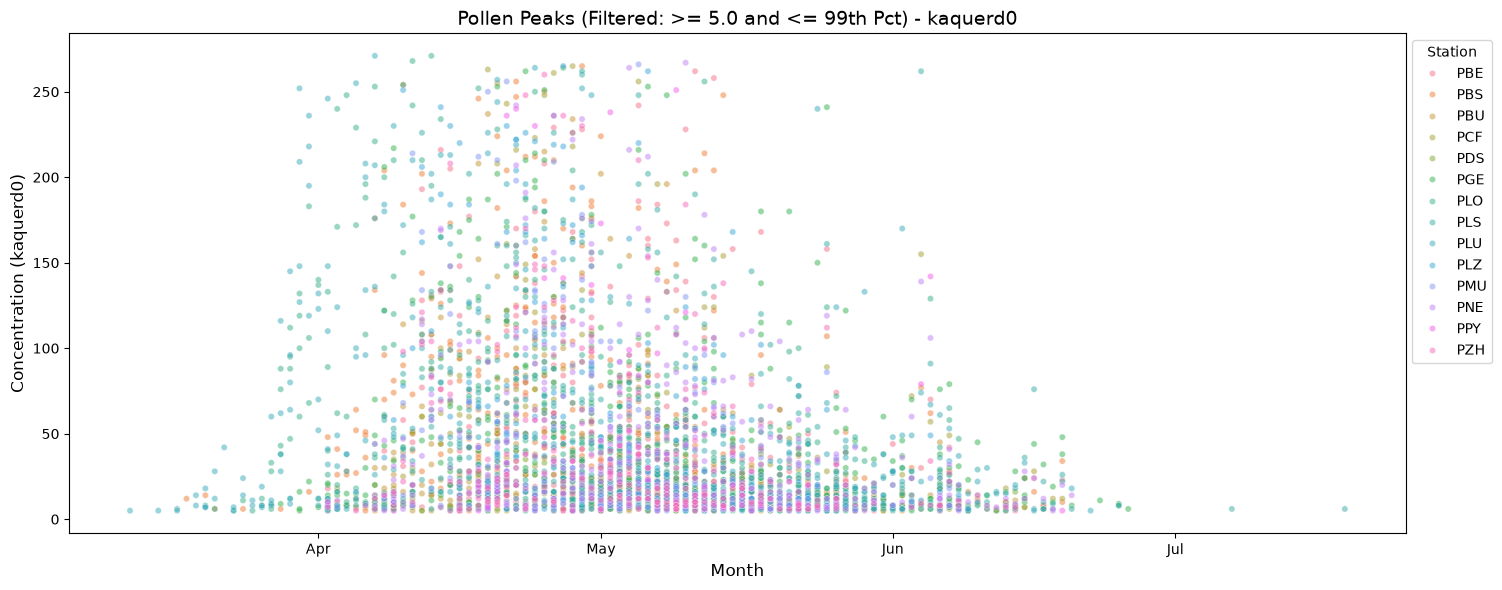

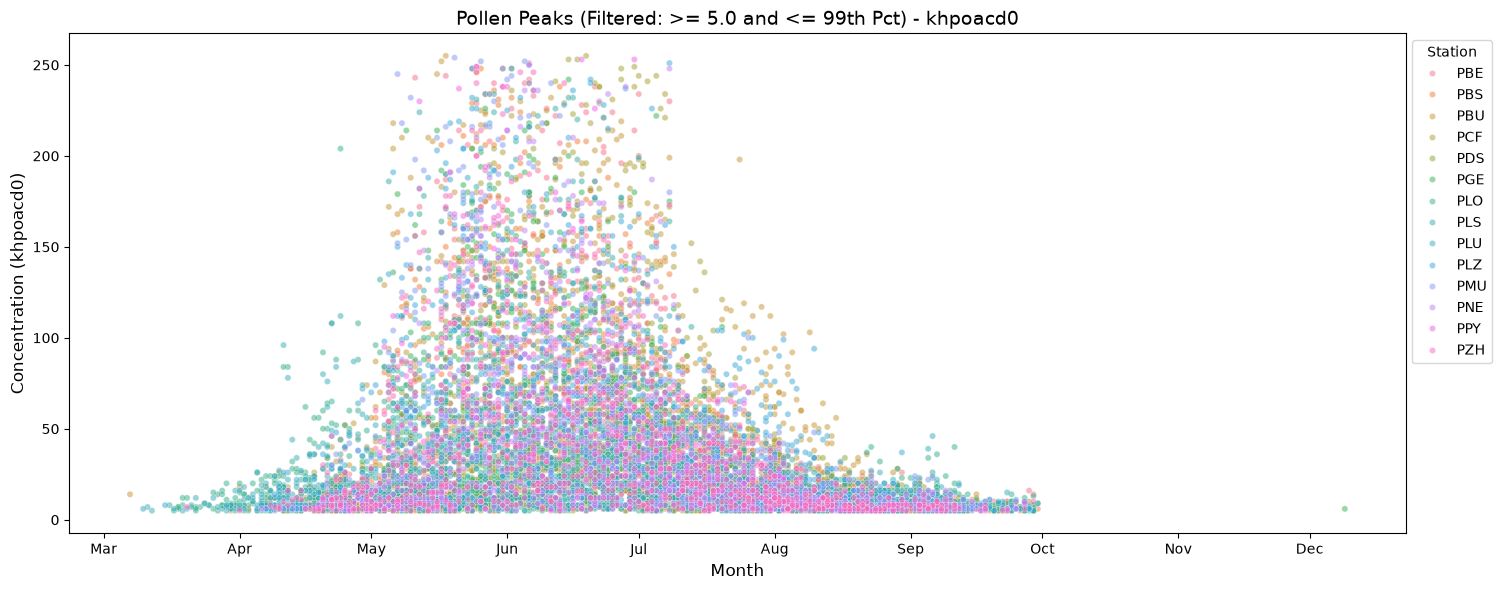

In [66]:
for feature in pollen_features:
    # 1. Define your lower threshold limit
    # Choose ONE of the following options:

    # Option A: Discard values lower than 10
    lower_limit = 5.0

    # Option B: Discard values lower than the 1st percentile (bottom 1%)
    # lower_limit = pdf[feature].quantile(0.10)

    # 2. Filter the DataFrame (keep only values >= your lower limit,
    # and optionally keep your upper 99th percentile cap too)
    upper_limit = pdf[feature].quantile(0.99)

    pdf_filtered = pdf[
        (pdf[feature] >= lower_limit) &
        (pdf[feature] <= upper_limit)
    ]

    # 3. Create your scatter plot with the cleaned subset
    plt.figure(figsize=(15, 6))
    sns.scatterplot(
        data=pdf_filtered,
        x="date_no_year",
        y=feature,
        hue="station_abbr",
        alpha=0.5,
        s=20
    )

    ax = plt.gca()
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

    plt.title(f"Pollen Peaks (Filtered: >= {lower_limit} and <= 99th Pct) - {feature}", fontsize=14)
    plt.xlabel("Month", fontsize=12)
    plt.ylabel(f"Concentration ({feature})", fontsize=12)
    plt.legend(bbox_to_anchor=(1.07, 1), loc="upper right", title="Station")
    plt.tight_layout()
    plt.show()